<a href="https://colab.research.google.com/github/jonathanxuningzhu/Deeplearning/blob/main/Linear%20Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch: 0 | Trainloss: 0.3129 | Testloss: 0.4932
Epoch: 1 | Trainloss: 0.3117 | Testloss: 0.4918
Epoch: 2 | Trainloss: 0.3106 | Testloss: 0.4905
Epoch: 3 | Trainloss: 0.3094 | Testloss: 0.4891
Epoch: 4 | Trainloss: 0.3083 | Testloss: 0.4878
Epoch: 5 | Trainloss: 0.3071 | Testloss: 0.4865
Epoch: 6 | Trainloss: 0.3060 | Testloss: 0.4851
Epoch: 7 | Trainloss: 0.3048 | Testloss: 0.4838
Epoch: 8 | Trainloss: 0.3037 | Testloss: 0.4824
Epoch: 9 | Trainloss: 0.3025 | Testloss: 0.4811
Epoch: 10 | Trainloss: 0.3014 | Testloss: 0.4797
Epoch: 11 | Trainloss: 0.3002 | Testloss: 0.4784
Epoch: 12 | Trainloss: 0.2991 | Testloss: 0.4770
Epoch: 13 | Trainloss: 0.2979 | Testloss: 0.4757
Epoch: 14 | Trainloss: 0.2968 | Testloss: 0.4743
Epoch: 15 | Trainloss: 0.2956 | Testloss: 0.4730
Epoch: 16 | Trainloss: 0.2944 | Testloss: 0.4716
Epoch: 17 | Trainloss: 0.2933 | Testloss: 0.4703
Epoch: 18 | Trainloss: 0.2921 | Testloss: 0.4689
Epoch: 19 | Trainloss: 0.2910 | Testloss: 0.4676
Epoch: 20 | Trainloss: 0.2898 

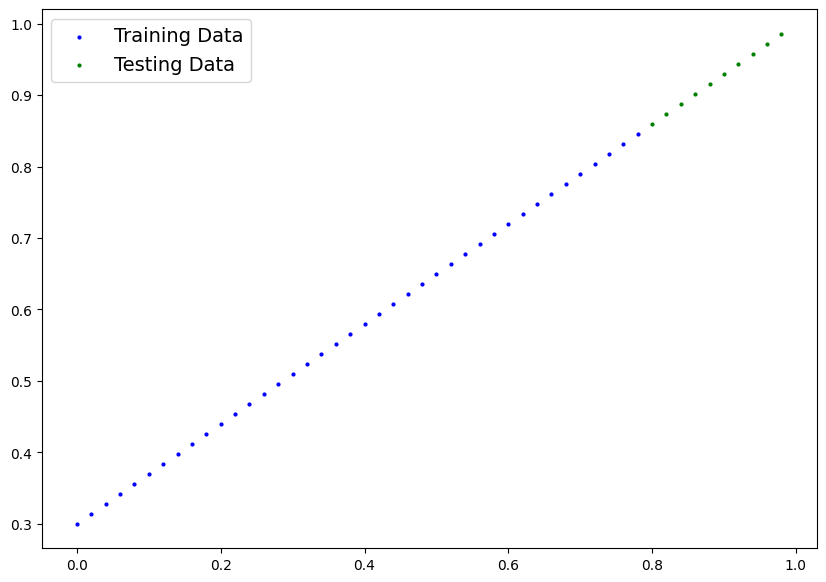

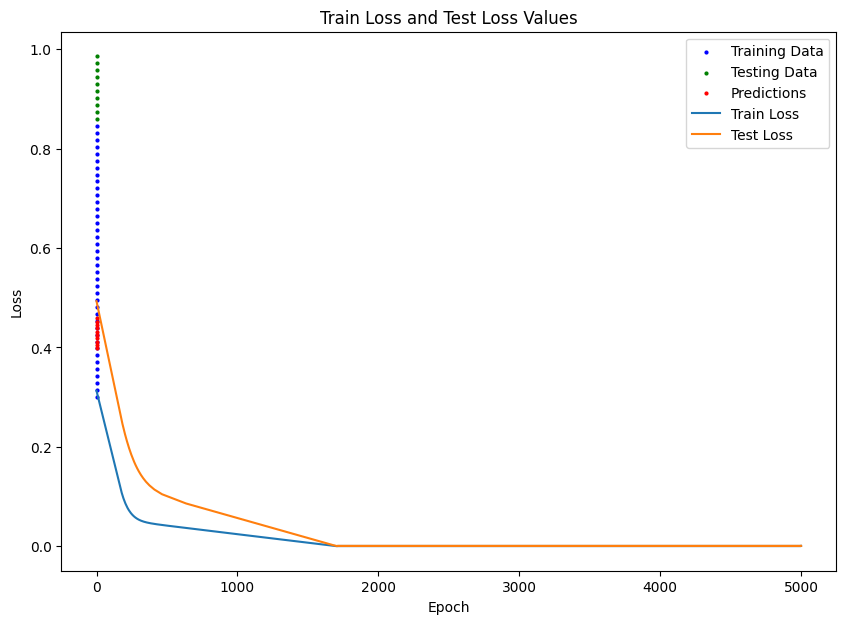

The model learned the following weights and biasesOrderedDict({'weights': tensor([0.6994]), 'bias': tensor([0.2998])})
The actual weights and biases are weights: 0.7, bias: 0.3


In [ ]:
from prompt_toolkit.shortcuts.progress_bar import Label
import torch
from torch import nn
import matplotlib.pyplot as plt

weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02

X = torch.arange(start,end,step).unsqueeze(dim = 1)

Y = weight*X + bias

train_split = int(0.8*len(X))

X_train,Y_train = X[:train_split],Y[:train_split]

X_test,Y_test = X[train_split:],Y[train_split:]


def plot_predictions(train_data = X_train,train_labels = Y_train,test_data = X_test, test_labels = Y_test,predictions = None,):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_labels,c="b",s = 4,label = "Training Data")
  plt.scatter(test_data,test_labels,c = "g",s = 4, label = "Testing Data")
  if predictions is not None:
    plt.scatter(test_data,predictions,c = "r",s = 4,label = "Predictions")

  plt.legend(prop = {"size" : 14})

plot_predictions()


class LinearRegressionModel(nn.Module):
  def __init__ (self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1,dtype = torch.float),requires_grad = True)

    self.bias = nn.Parameter(torch.randn(1,dtype = torch.float),requires_grad = True)

  def forward(self,x: torch.Tensor) -> torch.Tensor:
    return self.weights*x + self.bias

torch.manual_seed(42)

model_0 = LinearRegressionModel()

list(model_0.parameters())

model_0.state_dict


with torch.inference_mode():
  y_preds = model_0(X_test)

plot_predictions(predictions=y_preds)


loss_fn = nn.L1Loss()

optimizer = torch.optim.SGD(params=model_0.parameters(),lr=0.001)

epochs = 5000


epoch_count = []

test_loss_values = []

train_loss_values = []



for epochs in range(epochs):
  model_0.train()

  y_preds = model_0(X_train)

  loss = loss_fn(y_preds,Y_train)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  model_0.eval()

  with torch.inference_mode():
    test_preds = model_0(X_test)

    test_loss = loss_fn(test_preds,Y_test)

  #if epochs % 10 == 0:
    epoch_count.append(epochs)
    test_loss_values.append(test_loss.item())
    train_loss_values.append(loss.item())

    print(f"Epoch: {epochs} | Trainloss: {loss.item():.4f} | Testloss: {test_loss.item():.4f}")


plt.plot(epoch_count,train_loss_values,label = "Train Loss")
plt.plot(epoch_count,test_loss_values, label = "Test Loss")

plt.title("Train Loss and Test Loss Values")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()


print(f"The model learned the following weights and biases{model_0.state_dict()}")
print(f"The actual weights and biases are weights: {weight}, bias: {bias}")




In [ ]:
model_0.eval()

with torch.inference_mode():

  y_preds = model_0(X_test)

y_preds

tensor([[0.8593],
        [0.8733],
        [0.8873],
        [0.9013],
        [0.9152],
        [0.9292],
        [0.9432],
        [0.9572],
        [0.9712],
        [0.9852]])

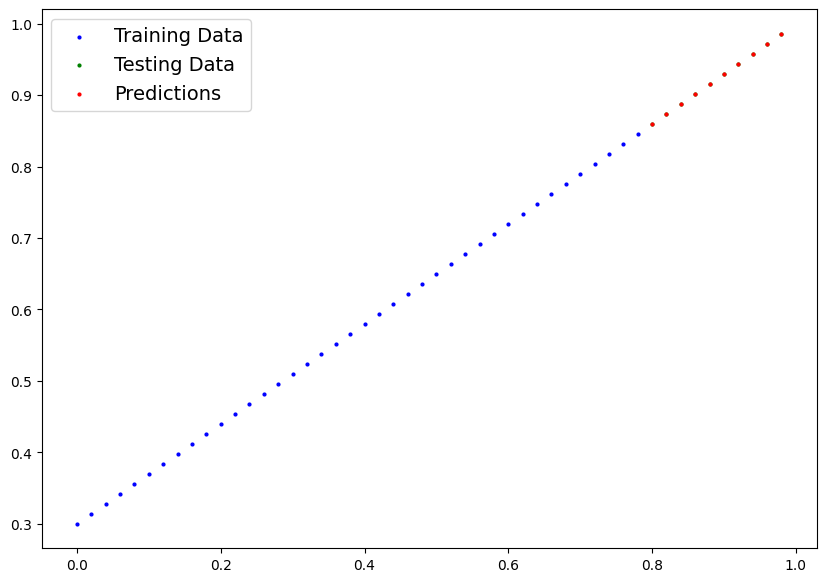

In [ ]:
plot_predictions(predictions=y_preds)